# Categorical and Time Signals

Two feature types get mishandled more than any others: categories and timestamps. This
notebook is about *seeing* the signal in both before doing anything clever with them.

For categories, the same question works whether the category has a natural order or not:
does the label's average rate actually move across categories, or is it flat? Plotting
that rate per category answers it directly, and the plot itself already tells you whether
the category is worth encoding at all.

For timestamps, the problem is different: a raw hour-of-day feature (0-23) lies to a model
about distance. Hour 23 and hour 0 are one hour apart in reality and twenty-three apart on
a number line. This notebook builds the sine/cosine fix and shows, on a real signal, why it
matters.

Target encoding, the natural next step once a categorical signal is confirmed, is
deliberately **not** covered here, it gets its own article. This one stops at seeing and
understanding the signal.

#### Configuration

In [1]:
from __future__ import annotations

import pandas as pd

from categorical_time_signals import (
    CategoricalTimeSignalPlotter,
    add_cyclical_hour_features,
    download_trip_data,
    prepare_trip_data,
)

# ── Sampling ─────────────────────────────────────────────────────────────────
SAMPLE_SIZE = 500_000   # rows kept after cleaning, out of ~2.9M in the source file
SEED        = 7         # reproducible sample, nothing else here is randomised


---
## 1. The dataset

[NYC Yellow Taxi Trip Records](https://www.nyc.gov/site/tlc/about/tlc-trip-record-data.page),
January 2024, published directly by the NYC Taxi & Limousine Commission as a public Parquet
file, no account or API key needed. One month is about 2.9 million trips with a pickup
timestamp, a payment method, a passenger count, a trip distance, and the fare/tip amounts
paid.

There is no pre-baked label here, every field used below is genuinely recorded by the
metering system. That matters for this article specifically: the whole point is spotting
*real* signal, not a signal engineered to exist.

In [2]:
raw_df = download_trip_data()
print(f"{len(raw_df):,} raw trips  |  columns: {list(raw_df.columns)}")

2,964,624 raw trips  |  columns: ['VendorID', 'tpep_pickup_datetime', 'tpep_dropoff_datetime', 'passenger_count', 'trip_distance', 'RatecodeID', 'store_and_fwd_flag', 'PULocationID', 'DOLocationID', 'payment_type', 'fare_amount', 'extra', 'mta_tax', 'tip_amount', 'tolls_amount', 'improvement_surcharge', 'total_amount', 'congestion_surcharge', 'Airport_fee']


In [3]:
raw_df.head()

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee
0,2,2024-01-01 00:57:55,2024-01-01 01:17:43,1.0,1.72,1.0,N,186,79,2,17.7,1.0,0.5,0.00,0.0,1.0,22.70,2.5,0.0
1,1,2024-01-01 00:03:00,2024-01-01 00:09:36,1.0,1.80,1.0,N,140,236,1,10.0,3.5,0.5,3.75,0.0,1.0,18.75,2.5,0.0
2,1,2024-01-01 00:17:06,2024-01-01 00:35:01,1.0,4.70,1.0,N,236,79,1,23.3,3.5,0.5,3.00,0.0,1.0,31.30,2.5,0.0
3,1,2024-01-01 00:36:38,2024-01-01 00:44:56,1.0,1.40,1.0,N,79,211,1,10.0,3.5,0.5,2.00,0.0,1.0,17.00,2.5,0.0
4,1,2024-01-01 00:46:51,2024-01-01 00:52:57,1.0,0.80,1.0,N,211,148,1,7.9,3.5,0.5,3.20,0.0,1.0,16.10,2.5,0.0


In [4]:
raw_df.dtypes

VendorID                          int32
tpep_pickup_datetime     datetime64[us]
tpep_dropoff_datetime    datetime64[us]
passenger_count                 float64
trip_distance                   float64
RatecodeID                      float64
store_and_fwd_flag                  str
PULocationID                      int32
DOLocationID                      int32
payment_type                      int64
fare_amount                     float64
extra                           float64
mta_tax                         float64
tip_amount                      float64
tolls_amount                    float64
improvement_surcharge           float64
total_amount                    float64
congestion_surcharge            float64
Airport_fee                     float64
dtype: object

---
## 2. From raw trips to a labelled, sampled table

Three things happen in `prepare_trip_data`, all on real columns:

1. **The label.** `well_tipped` = 1 if the tip was at least 20% of the fare. This only
   means something for credit-card trips: cash tips are essentially never logged by the
   metering system, so a cash trip reads as "$0 tip" whether or not cash actually changed
   hands. That quirk turns out to be the first signal worth seeing, not a nuisance to clean
   away.
2. **The ordinal category.** `distance_tier` buckets `trip_distance` into 5 ordered bands,
   `0-1 mi` through `8+ mi`. Binning a continuous variable into ordered bands like this is
   a completely standard way to *get* an ordinal categorical in the first place.
3. **The time column.** `hour`, the pickup hour, 0 through 23, is what Sections 5 and 6
   revisit.


In [5]:
df = prepare_trip_data(
    raw_df, 
    sample_size=SAMPLE_SIZE,
    seed=SEED)
plotter = CategoricalTimeSignalPlotter()

print(f"{len(df):,} trips after cleaning and sampling")
print(f"Overall well-tipped rate: {df['well_tipped'].mean():.1%}")
df.head()


500,000 trips after cleaning and sampling
Overall well-tipped rate: 63.8%


,tpep_pickup_datetime,hour,payment_type,distance_tier,trip_distance,fare_amount,tip_amount,tip_pct,passenger_count,well_tipped,airport_fee_flag,store_and_fwd_flag_bin
0,2024-01-26 19:26:42,19,Credit card,1-2 mi,1.18,10.0,3.3,0.330000,1.0,1,0,0
1,2024-01-19 12:54:28,12,Credit card,0-1 mi,0.94,10.0,0.0,0.000000,1.0,0,0,0
2,2024-01-21 17:21:20,17,Credit card,8+ mi,16.98,83.9,5.0,0.059595,2.0,0,0,0
3,2024-01-10 23:26:35,23,Cash,4-8 mi,5.22,24.0,0.0,0.000000,1.0,0,0,0
4,2024-01-16 17:19:32,17,Credit card,4-8 mi,5.59,45.0,10.3,0.228889,1.0,1,0,0


---
## 3. A nominal category: `payment_type`

`payment_type` has no natural order, Credit card, Cash, Dispute, No charge are just four
different ways a trip got paid for. The plot below sorts the bars by rate instead of
keeping any particular order, because there isn't one to keep.

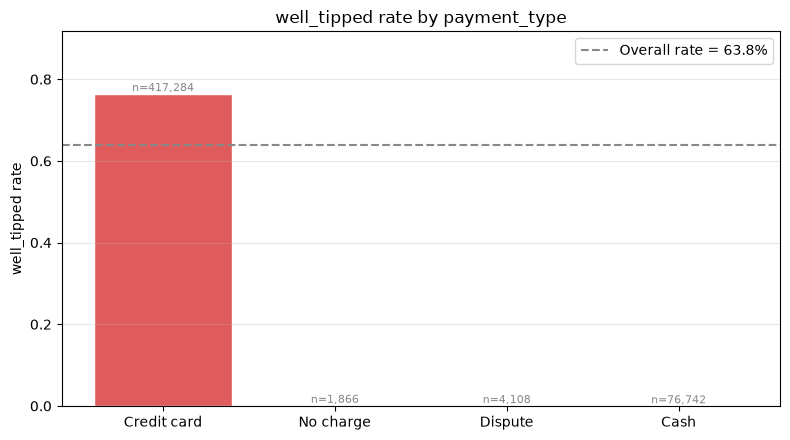

In [6]:
_ = plotter.plot_category_rate(df, category_col="payment_type", label_col="well_tipped")
_.savefig("img/payment_type_rate.png", dpi=150, bbox_inches="tight")


This is about as strong as a categorical signal gets, credit-card trips are "well tipped"
76% of the time, every other payment method is close to 0%. Before reading that as "cash
riders don't tip", remember how the label was built: cash tips are essentially invisible to
the system that generated this dataset, at $0 recorded tip, a cash trip and a genuinely
untipped credit-card trip look identical. The signal is completely real and completely
usable, it just reflects *how the label was recorded* as much as it reflects rider
behaviour. That distinction matters before anyone builds on top of this column, a strong
categorical signal is not automatically a strong *causal* one.

Because payment type dominates everything else this hard, the two sections below condition
on `payment_type == "Credit card"` throughout, otherwise this one column would drown out
every other signal in the data.

In [7]:
credit_card_df = df[df["payment_type"] == "Credit card"].copy()
print(f"{len(credit_card_df):,} credit-card trips")

417,284 credit-card trips


---
## 3b. Two more binary flags: any split less skewed than `payment_type`?

`payment_type` splits 83% / 15% / &lt;1% / &lt;1%, one category drowning out the rest. Two
other fields in the raw file are naturally binary, so it's worth checking whether either
one gives a more balanced split to work with:

* **`airport_fee_flag`** — 1 if `Airport_fee` is recorded as anything other than `NaN` or
  `0` (a nonzero airport fee was actually charged), 0 otherwise.
* **`store_and_fwd_flag_bin`** — 1 if `store_and_fwd_flag == "Y"`, 0 for everything else
  (`"N"` or missing). `Y` (store-and-forward trip): the trip record was held in vehicle
  memory because the taxi lacked a live connection to the server at the time, and was sent
  out later once connectivity was restored.



A real gap, but nowhere near `payment_type`'s: airport trips (`airport_fee_flag == 1`)
are "well tipped" 56.6% of the time, against 64.5% for everything else, an ~8-point drop
from the 63.8% baseline. Part of that is payment mix, not rider behaviour, airport trips
run slightly more cash-heavy (19% vs. 15%), and cash tips are the same invisible-to-the-
meter problem `payment_type` already surfaced. Restricting to credit-card trips only
narrows the gap to 76.8% vs. 71.8%, still real, just smaller.

This also previews the next section below: airport trips average 13.6 miles, squarely
inside the `8+ mi` distance tier, so when that ordinal breakdown shows the longest-trip
band ticking back up against an otherwise clean downward trend, airport runs are the most
likely reason. They still tip below the credit-card baseline here, just not by nearly as
much as the short-to-mid-distance drop-off alone would predict, flat-rate airport fares
don't follow the usual "tip shrinks as the bill grows" pattern as cleanly.

In [8]:
for col in ["payment_type", "airport_fee_flag", "store_and_fwd_flag_bin"]:
    print(f"--- {col} ---")
    print((df[col].value_counts(normalize=True) * 100).round(2).astype(str) + "%")
    print()

--- payment_type ---
payment_type
Credit card    83.46%
Cash           15.35%
Dispute         0.82%
No charge       0.37%
Name: proportion, dtype: str

--- airport_fee_flag ---
airport_fee_flag
0    91.65%
1     8.35%
Name: proportion, dtype: str

--- store_and_fwd_flag_bin ---
store_and_fwd_flag_bin
0    99.62%
1     0.38%
Name: proportion, dtype: str



* `store_and_fwd_flag_bin` lands at roughly 99.6% / 0.4%, close to a constant column.
  Store-and-forward only fires when the taxi's connection actually dropped, a rare
  operational glitch rather than something tied to how or where someone rode.

It is too skewed and it would not be considered

`airport_fee_flag`'s own rate plot, same read as Section 3's: does `well_tipped`
actually move between the two categories, or is it flat? Then both flags' splits, measured
against `payment_type`'s.

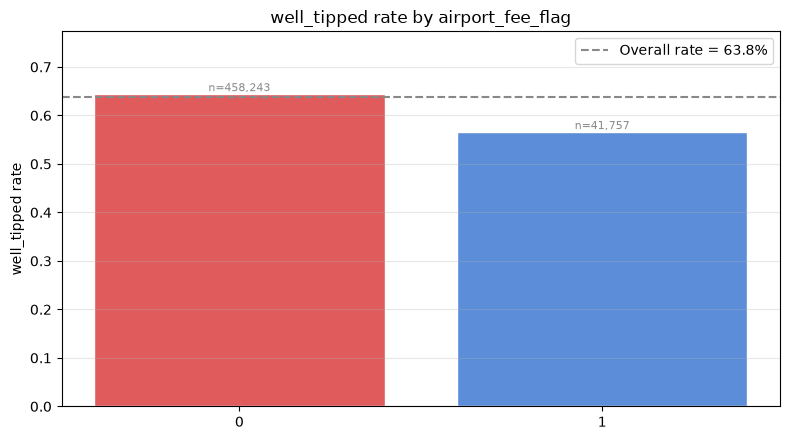

In [9]:
_ = plotter.plot_category_rate(df, category_col="airport_fee_flag", label_col="well_tipped")
_.savefig("img/airport_fee_flag_rate.png", dpi=150, bbox_inches="tight")


---
## 4. An ordinal category: `distance_tier`

`distance_tier` does have a natural order, short trips to long trips, and that order is
exactly what the plot should preserve. Passing `order=` keeps the bars in that sequence
instead of sorting by rate, a trend along the order is the whole reason to look.

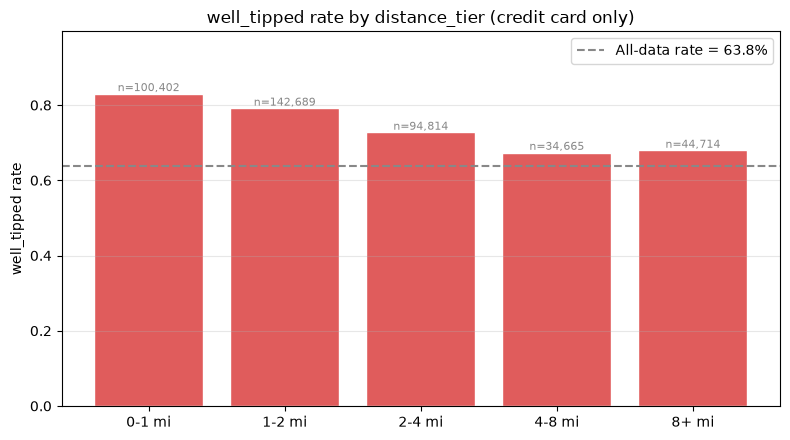

In [10]:
from categorical_time_signals.data import DISTANCE_TIER_LABELS

_ = plotter.plot_category_rate(
    credit_card_df,
    category_col="distance_tier",
    label_col="well_tipped",
    order=DISTANCE_TIER_LABELS,
    title="well_tipped rate by distance_tier (credit card only)",
    overall_df=df,
)
_.savefig("img/distance_tier_rate.png", dpi=150, bbox_inches="tight")

A clean downward trend for the first four bands, short trips are tipped generously,
longer trips less so, consistent with well-documented tipping behaviour outside taxis too:
percentage tips shrink as the bill grows, because riders anchor on a roughly fixed dollar
amount rather than scaling the tip with the fare. The `8+ mi` band breaks the pattern
slightly, it ticks back up. That's plausibly the airport/flat-rate trips in this bucket,
where the usual "tip shrinks as the bill grows" logic applies less cleanly, Section 3b
confirms this directly with the real `Airport_fee` field rather than guessing from
distance alone: airport trips still tip below the credit-card baseline, just not by nearly
as much as the short-to-mid-distance drop-off on its own would predict. A real ordinal
signal does not have to be perfectly monotonic to be worth using, but a break in the trend
like this one is worth explaining, not silently averaging away.

Both signals above are exactly what a model would want to exploit, and exactly what
**target encoding** turns into a numeric feature safely. That's a big enough topic for its
own article; this one stops at confirming the signal exists.

---
## 5. A time column, the naive way

`hour` looks like an ordinary numeric feature, 0 through 23, so it's tempting to treat it
like one. Plotting the label's rate against raw hour is the natural first move.

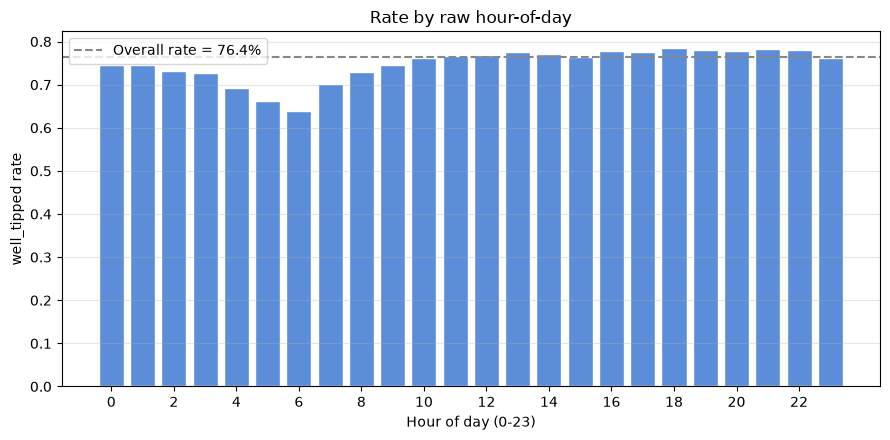

In [11]:
_ = plotter.plot_hour_rate_linear(credit_card_df, label_col="well_tipped")
_.savefig("img/hour_rate_linear.png", dpi=150, bbox_inches="tight")


There is a real pattern here: a dip in the early morning (lowest around 6 AM) and a
plateau through the afternoon and evening. But look at the two ends of the bar chart,
hour 23 and hour 0 sit at opposite edges of the plot, as far apart as two bars can be,
despite being one hour apart on an actual clock. Anything a model learns "at the edges" of
this feature, a threshold, a linear trend, a tree split, treats 23 and 0 as maximally
different when they are, in reality, adjacent. A raw hour feature is lying about distance.

---
## 6. Fixing the distance: sine and cosine

The fix is to stop representing "hour" as a position on a line and represent it as a
position on a *circle* instead, exactly like a clock face. Map each hour to an angle
around the circle, then read off that angle's `(cos, sin)` coordinates:

```python
angle = 2 * pi * hour / 24
hour_sin = sin(angle)
hour_cos = cos(angle)
```

Two hours that are close on the clock, like 23:00 and 01:00, land close together in
`(hour_sin, hour_cos)` space too, because they *are* close together on the circle the
formula is built from. Hour 0 and hour 12, the two times as far apart as a 24-hour clock
allows, land on opposite sides of the circle. The encoding isn't a trick, it's just
plotting the hour where a clock already puts it.

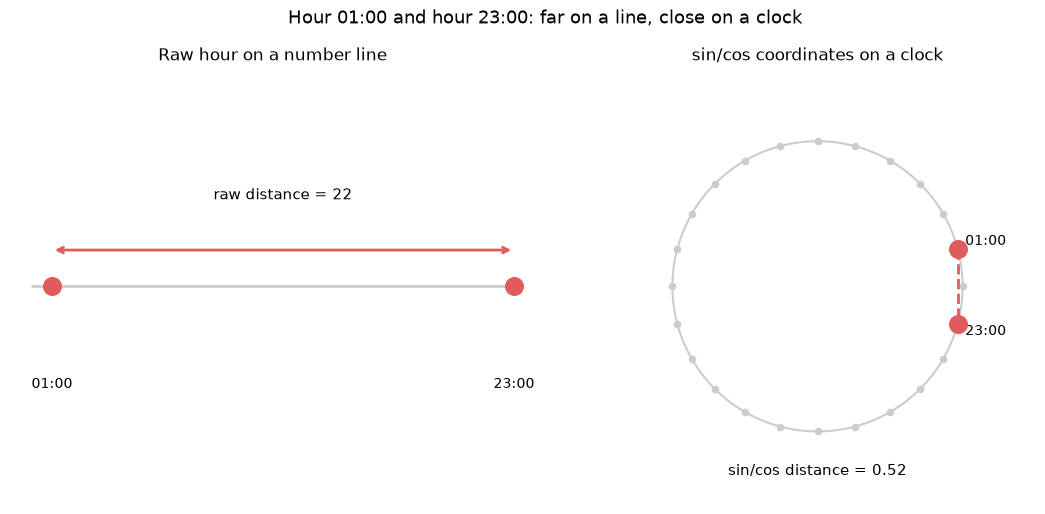

In [12]:
_ = plotter.plot_hour_distance_illustration(hour_a=1, hour_b=23)
_.savefig("img/hour_distance_illustration.png", dpi=150, bbox_inches="tight")


Left: 1:00 and 23:00 on a plain number line, 22 apart, aliased as almost the two most
distant points the feature can take. Right: the same two hours placed on a clock by their
`(cos, sin)` coordinates, visibly a short arc apart. Same two timestamps, two different
stories about how far apart they are, only one of them matches the calendar.

In [13]:
df = add_cyclical_hour_features(df, hour_col="hour")
credit_card_df = add_cyclical_hour_features(credit_card_df, hour_col="hour")

import numpy as np

def hour_distance(hour_a: int, hour_b: int) -> tuple[float, float]:
    raw = abs(hour_a - hour_b)
    angle_a, angle_b = 2 * np.pi * hour_a / 24, 2 * np.pi * hour_b / 24
    cyclical = np.hypot(np.cos(angle_a) - np.cos(angle_b), np.sin(angle_a) - np.sin(angle_b))
    return raw, cyclical

for pair in [(1, 23), (0, 12), (9, 17)]:
    raw, cyclical = hour_distance(*pair)
    print(f"hour {pair[0]:>2} vs hour {pair[1]:>2}:  raw distance = {raw:>2}   sin/cos distance = {cyclical:.2f}")


hour  1 vs hour 23:  raw distance = 22   sin/cos distance = 0.52
hour  0 vs hour 12:  raw distance = 12   sin/cos distance = 2.00
hour  9 vs hour 17:  raw distance =  8   sin/cos distance = 1.73


1 and 23 are 22 apart on the raw feature, worse than almost any other pair on a 24-hour
clock, but only 0.52 apart in `(sin, cos)` space, among the *closest* pairs possible, which
matches how close 1 AM and 11 PM actually are. 0 and 12, truly opposite ends of the day, get
the largest possible cyclical distance (2.0), while the raw feature ranks that pair as only
moderately far apart. 9 and 17, a genuinely ordinary 8-hour gap, land somewhere in between
on both scales, raw distance and clock distance agree once the two hours are far enough
apart that wraparound isn't the deciding factor. Wraparound is the whole issue, and it only
bites near the boundary.

Now the same rates from Section 5, arranged on the clock they actually describe:

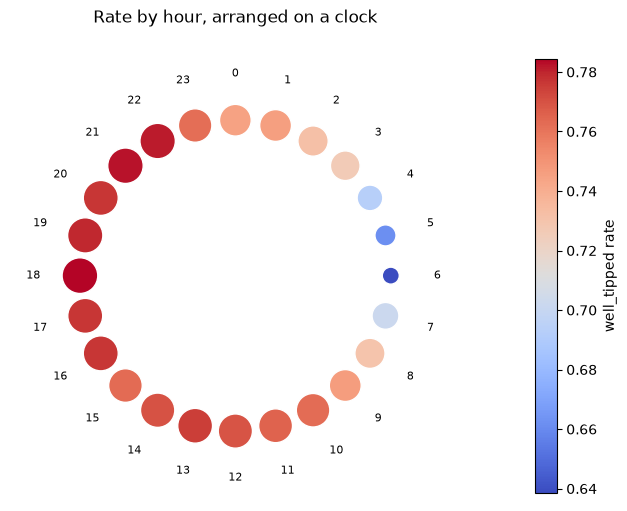

In [14]:
_ = plotter.plot_hour_clock(credit_card_df, label_col="well_tipped")
_.savefig("img/hour_clock.png", dpi=150, bbox_inches="tight")


The early-morning dip and the daytime plateau are the same pattern as the bar chart, but
now hour 23 and hour 0 sit next to each other, because they are next to each other. The
gradual colour change all the way around the circle, rather than a hard seam at midnight,
is what a well-behaved cyclical feature should look like, and it's exactly what
`hour_sin` / `hour_cos` hands to a model instead of the raw hour column.

---
## 7. The takeaway

Two different problems, two different fixes, and neither one needs a model trained to be
worth checking:

* **A categorical column's signal is visible in one plot.** Rate per category, ordered if
  the category has an order, sorted by rate if it doesn't. If the bars are flat, the
  category has little to offer; if they're not, look for *why* before assuming the story is
  as simple as it looks (Section 3's payment-type caveat is the cautionary example).
* **A cyclical column lies about distance if left as a plain number.** Any time-of-day,
  day-of-week, or day-of-year feature has the same wraparound problem hour did here, and
  the same `sin`/`cos` fix. The test is simple: if the two ends of the range are actually
  adjacent in reality, the raw numeric encoding is wrong, no model architecture fixes that
  on its own.

Turning a confirmed categorical signal into a numeric feature safely, without leaking the
label into itself, is target encoding, and it's substantial enough to deserve its own
article rather than a rushed final section here.